# EF_mu0mlvtx with the prompt-track veto: efficiency, rate, unique rate and time

Same study as `dv_score_eff.ipynb`, with step 3 of the chain: full-scan tracking (shared with the jet chains) and a veto on
prompt tracks pointing to the DV direction (`MlMuonDVtxTrkVetoHypoTool`: leading muon-segment cluster, track
pT > 5 GeV, ΔR < 0.4, |Δz0 sinθ| < 2 mm to the hard-scatter vertex).

The jobs run with a **lowered step-2 score cut** (`run_dv_rates.sh --scoreCut`), so the chain decision is
"score ≥ cut_jobs AND veto", and each event has its DV score in the job log. For any score cut c ≥ cut_jobs:
- **GNN only**: score > c
- **GNN + track veto**: chain decision AND score > c

cut_jobs = 0.5 for Run-4 MC (`l1eff_trkveto`), 0.8 for EB data (`rates_eb500306_trkveto`), all in `Inference_DisplacedVtx/test_rate_trackVeto`.
Release: nightly 2026-11-09 (25.0.80), as `dv_score_eff.ipynb` (chain without the veto, `test_rate_noTrackVeto`).

**L1_MU3V is required explicitly** (score and chain decision set to fail without it). Step 3 is seeded with `FSNOSEED`,
and in Run-4 MC the chain then also runs on events without L1_MU3V (the MC L1 item is not a gate); in EB data it runs only on
L1_MU3V events, as the chain without the veto. Requiring the bit gives the same event set as `dv_score_eff.ipynb`.

In [1]:
import csv, glob, os
import numpy as np
import matplotlib.pyplot as plt
from contextlib import nullcontext

try:
    import mplhep as hep
except ImportError:
    hep = None

DV_DIR = "/eos/project-f/fcc-ml/ddicroce/ATLAS_MuonSpectrometer/KubeFlow/Inference_DisplacedVtx"
OUT_DIR = f"{DV_DIR}/test_rate_trackVeto"             # all outputs of this study
L1_DIR = f"{OUT_DIR}/l1eff_trkveto"                  # MC: test_rate/run_mc_eff_trkveto.sh
EB_OUT = f"{OUT_DIR}/rates_eb500306_trkveto"          # EB data: run_dv_rates.sh + dv_seed_scan.py
UNIQUE_OUT = f"{OUT_DIR}/unique_eb500306_trkveto"      # run_dv_unique.sh
NOVETO_DIR = f"{DV_DIR}/test_rate_noTrackVeto"        # same release without the veto (cost comparison)
MC_JOB_CUT, EB_JOB_CUT = 0.5, 0.8                          # step-2 score cut of the jobs (--scoreCut)

# sample dir -> (label, is_signal); colours follow this order (fixed, not by rank)
SAMPLES = {
    "Haa4mu_m8_ctau500_mu200":    (r"H$\to$aa$\to$4$\mu$, $m_a$=8 GeV, c$\tau$=500 mm", True),
    "a_mumu_m2_ctau100_mu200":    (r"a$\to\mu\mu$, $m_a$=2 GeV, c$\tau$=100 mm", True),
    "a_mumu_m8_ctau500_mu200":    (r"a$\to\mu\mu$, $m_a$=8 GeV, c$\tau$=500 mm", True),
    "a_mumu_m100_ctau5000_mu200": (r"a$\to\mu\mu$, $m_a$=100 GeV, c$\tau$=5000 mm", True),
    "Zmumu_mu200":                (r"Z$\to\mu\mu$", False),
    "ttbar_mu200":                (r"$t\bar{t}$", False),
    "JPSI_mu200":                 (r"J/$\psi\to\mu\mu$", False),
}
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]

SEEDS = ["L1_MU3V", "L1_MU14FCH", "L1_2MU8F"]  # L1_MU3V = chain seed (None = no L1 requirement)
NOMINAL_CUT = 0.94
CUTS = np.linspace(0.5, 0.995, 100)

def plot_context():
    """ATLAS plot style (mplhep), as in DisplacedVertex_results_plots.ipynb"""
    return plt.style.context(hep.style.ATLAS) if hep is not None else nullcontext()

def atlas_header(ax, sample_label=None, data=False, fontsize=11):
    """'ATLAS Simulation Internal' (or 'ATLAS Internal' for data) and a sample label below it"""
    anchor = None
    if hep is not None:
        anchor = hep.atlas.label("Internal", ax=ax, data=data, loc=1, rlabel="", fontsize=fontsize + 2)[0]  # sqrt(s) is in sample_label
    if sample_label:
        # x in axes coordinates, y a few points below the ATLAS label (same gap for any figure size)
        ax.annotate(sample_label, xy=(0.04, 0), xycoords=(ax.transAxes, anchor) if anchor else ax.transAxes,
                    xytext=(0, -6), textcoords="offset points", va="top", ha="left", fontsize=fontsize)

MC_LABEL = r"$\sqrt{s}$ = 14 TeV, $\langle\mu\rangle$ = 200"

In [2]:
L1_ITEMS = None

def load(sample):
    """per-event DV score (-1: none), chain decision (score >= MC_JOB_CUT AND veto) and L1 bits {item: bool array},
    from the seed tables. Events without L1_MU3V fail (the chain seed, see the introduction)"""
    global L1_ITEMS
    sc, ch, bits = [], [], []
    for path in sorted(glob.glob(f"{L1_DIR}/{sample}/hlt/job_*/seed_table.txt")):
        with open(path) as fh:
            for line in fh:
                if line.startswith("#"):
                    L1_ITEMS = line[1:].split()[4:]
                    continue
                f = line.split()
                ch.append(int(f[2]))
                sc.append(float(f[3]))
                bits.append([int(b) for b in f[4:]])
    bits = np.array(bits, dtype=bool)
    l1 = {it: bits[:, k] for k, it in enumerate(L1_ITEMS)}
    mu3v = l1["L1_MU3V"]
    print(f"{sample:28s} chain without L1_MU3V in {np.count_nonzero(np.array(ch, dtype=bool) & ~mu3v)} events (set to fail)")
    return np.where(mu3v, sc, -1.0), np.array(ch, dtype=bool) & mu3v, l1

data = {s: load(s) for s in SAMPLES}
for s, (sc, ch, l1) in data.items():
    print(f"{s:28s} {len(sc):5d} events, score > {NOMINAL_CUT}: GNN only {np.mean(sc > NOMINAL_CUT):.3f}, "
          f"+ track veto {np.mean(ch & (sc > NOMINAL_CUT)):.3f}")


Haa4mu_m8_ctau500_mu200      chain without L1_MU3V in 7 events (set to fail)
a_mumu_m2_ctau100_mu200      chain without L1_MU3V in 80 events (set to fail)
a_mumu_m8_ctau500_mu200      chain without L1_MU3V in 51 events (set to fail)
a_mumu_m100_ctau5000_mu200   chain without L1_MU3V in 433 events (set to fail)
Zmumu_mu200                  chain without L1_MU3V in 160 events (set to fail)
ttbar_mu200                  chain without L1_MU3V in 126 events (set to fail)
JPSI_mu200                   chain without L1_MU3V in 6 events (set to fail)
Haa4mu_m8_ctau500_mu200       2000 events, score > 0.94: GNN only 0.947, + track veto 0.900
a_mumu_m2_ctau100_mu200       2000 events, score > 0.94: GNN only 0.665, + track veto 0.641
a_mumu_m8_ctau500_mu200       2000 events, score > 0.94: GNN only 0.780, + track veto 0.743
a_mumu_m100_ctau5000_mu200    2000 events, score > 0.94: GNN only 0.476, + track veto 0.458
Zmumu_mu200                   2000 events, score > 0.94: GNN only 0.053, + track veto

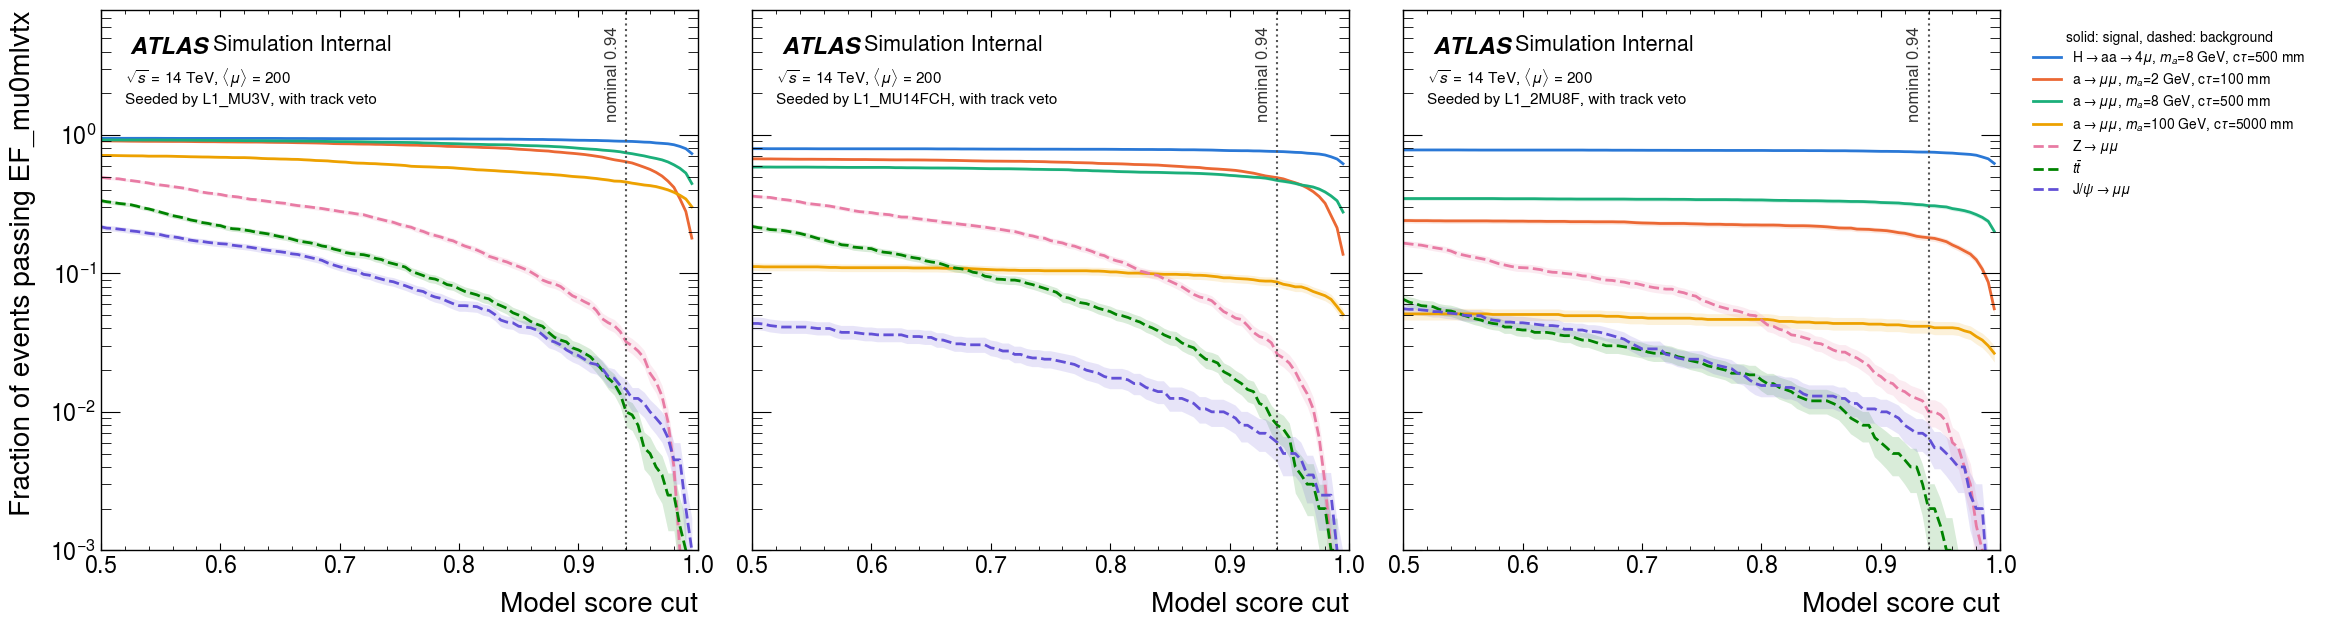

In [3]:
def efficiency(sample, seed, cuts, veto=True):
    """fraction of events with score > c (and the chain decision, i.e. the veto, if veto)"""
    sc, ch, l1 = data[sample]
    ok = np.ones(len(sc), dtype=bool) if seed is None else l1[seed]
    if veto:
        ok = ok & ch
    sel = np.where(ok, sc, -1.0)
    n = len(sc)
    eff = np.array([np.count_nonzero(sel > c) / n for c in cuts])
    return eff, np.sqrt(eff * (1 - eff) / n)

def plot_efficiency(ax, seed, fontsize=11):
    for (sample, (label, is_sig)), color in zip(SAMPLES.items(), COLORS):
        eff, err = efficiency(sample, seed, CUTS)
        ok = eff > 0  # log scale: drop empty points
        ax.plot(CUTS[ok], eff[ok], color=color, lw=2, ls="-" if is_sig else "--", label=label)
        ax.fill_between(CUTS[ok], (eff - err)[ok], (eff + err)[ok], color=color, alpha=0.15, lw=0)
    ax.axvline(NOMINAL_CUT, color="#555555", lw=1.5, ls=":")
    # x in data, y in axes coordinates; a few points left of the line, whatever the y range
    ax.annotate(f"nominal {NOMINAL_CUT}", xy=(NOMINAL_CUT, 0.97), xycoords=ax.get_xaxis_transform(),
                xytext=(-4, 0), textcoords="offset points", color="#333333", fontsize=fontsize + 1,
                ha="right", va="top", rotation=90)
    ax.set_xlabel("Model score cut")
    ax.set_yscale("log")
    ax.set_ylim(1e-3, 8)  # headroom for the ATLAS label
    seed_label = ("No L1 requirement" if seed is None else f"Seeded by {seed}") + ", with track veto"
    atlas_header(ax, f"{MC_LABEL}\n{seed_label}", fontsize=fontsize)

with plot_context():
    fig, axes = plt.subplots(1, len(SEEDS), figsize=(6.5 * len(SEEDS) + 4, 6.5), sharey=True)
    for ax, seed in zip(axes, SEEDS):
        plot_efficiency(ax, seed)
    axes[0].set_ylabel("Fraction of events passing EF_mu0mlvtx")
    axes[-1].legend(fontsize=10, frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1),
                    title="solid: signal, dashed: background", title_fontsize=10)
    fig.tight_layout()
    plt.show()

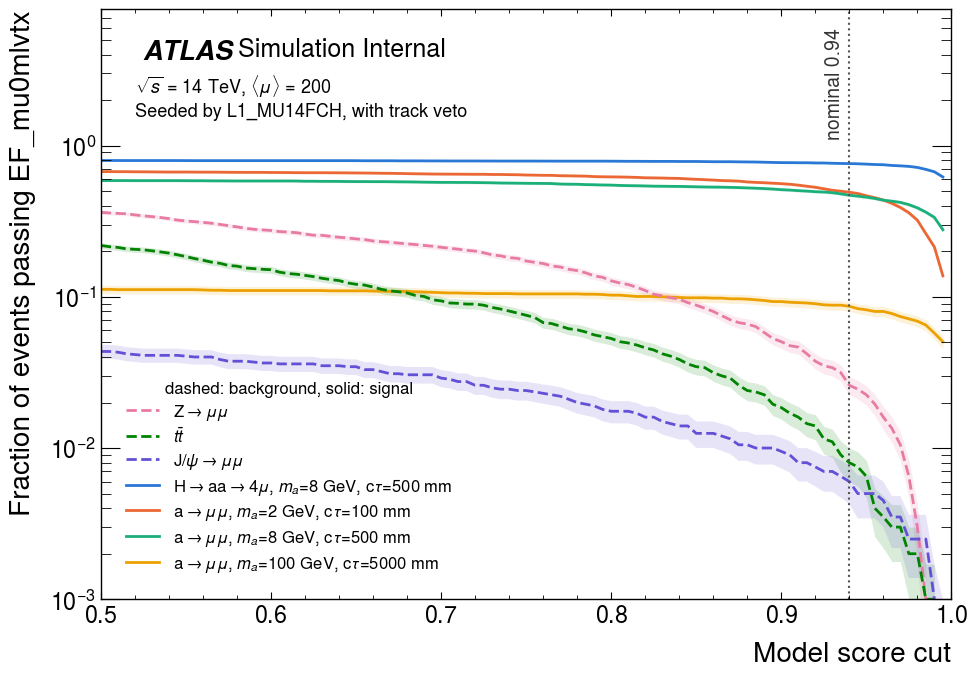

In [4]:
# Same, L1_MU14FCH seed only
with plot_context():
    fig, ax = plt.subplots(figsize=(10, 7))
    plot_efficiency(ax, "L1_MU14FCH", fontsize=13)
    ax.set_ylabel("Fraction of events passing EF_mu0mlvtx")
    # Inside, in the empty lower left: backgrounds first, their short labels sit next to the curves
    handles, labels = ax.get_legend_handles_labels()
    order = [k for k, (_, is_sig) in enumerate(SAMPLES.values()) if not is_sig] + \
            [k for k, (_, is_sig) in enumerate(SAMPLES.values()) if is_sig]
    ax.legend([handles[k] for k in order], [labels[k] for k in order], fontsize=12, frameon=False,
              loc="lower left", title="dashed: background, solid: signal", title_fontsize=12)
    fig.tight_layout()
    plt.show()

### Effect of the track veto
Solid: GNN + track veto, thin dashed: GNN only (same colour per sample), seeded by L1_MU14FCH.

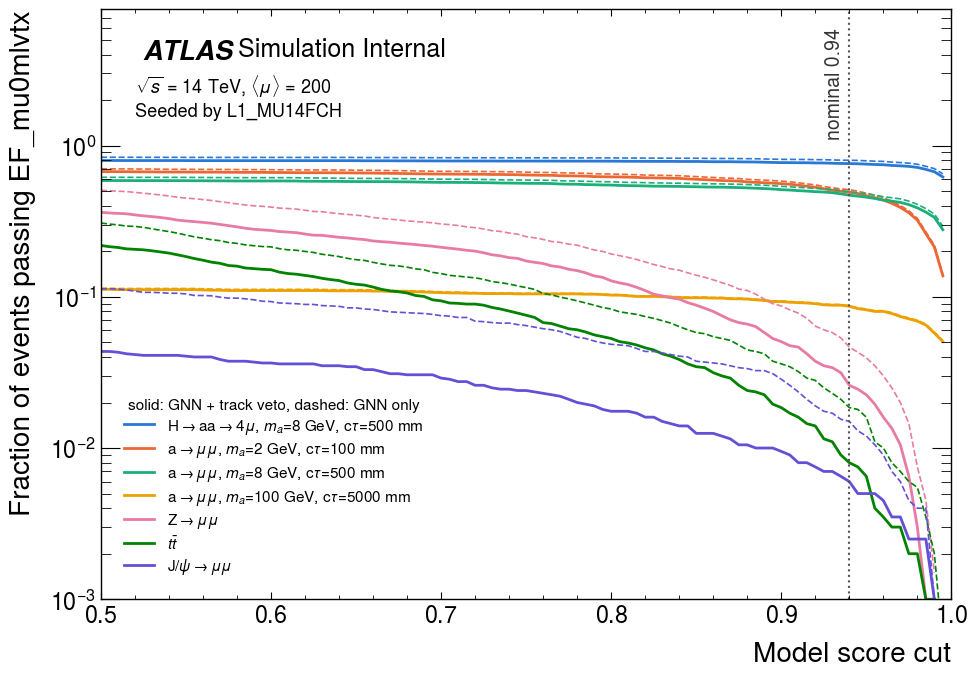

In [5]:
with plot_context():
    fig, ax = plt.subplots(figsize=(10, 7))
    for (sample, (label, is_sig)), color in zip(SAMPLES.items(), COLORS):
        for veto, ls, lw in ((False, "--", 1.2), (True, "-", 2)):
            eff, _ = efficiency(sample, "L1_MU14FCH", CUTS, veto=veto)
            ok = eff > 0
            ax.plot(CUTS[ok], eff[ok], color=color, lw=lw, ls=ls, label=label if veto else None)
    ax.axvline(NOMINAL_CUT, color="#555555", lw=1.5, ls=":")
    ax.annotate(f"nominal {NOMINAL_CUT}", xy=(NOMINAL_CUT, 0.97), xycoords=ax.get_xaxis_transform(),
                xytext=(-4, 0), textcoords="offset points", color="#333333", fontsize=14, ha="right", va="top", rotation=90)
    ax.set_yscale("log")
    ax.set_ylim(1e-3, 8)
    ax.set_xlabel("Model score cut")
    ax.set_ylabel("Fraction of events passing EF_mu0mlvtx")
    atlas_header(ax, f"{MC_LABEL}\nSeeded by L1_MU14FCH", fontsize=13)
    ax.legend(fontsize=11, frameon=False, loc="lower left", title="solid: GNN + track veto, dashed: GNN only", title_fontsize=11)
    fig.tight_layout()
    plt.show()

# Fraction kept by the veto at the nominal cut, per seed
rows = {}
for sample in SAMPLES:
    for seed in SEEDS:
        e0, _ = efficiency(sample, seed, [NOMINAL_CUT], veto=False)
        e1, _ = efficiency(sample, seed, [NOMINAL_CUT], veto=True)
        rows[(SAMPLES[sample][0], seed or "no L1")] = {"GNN only": 100 * e0[0], "GNN + veto": 100 * e1[0],
                                                       "kept by veto": 100 * e1[0] / e0[0] if e0[0] else np.nan}
import pandas as pd
pd.DataFrame(rows).T.style.format("{:.1f}%").set_caption(f"Efficiency at score > {NOMINAL_CUT}")

In [6]:
# Same numbers as a table at a few cuts (GNN + track veto)
TABLE_CUTS = [0.5, 0.8, 0.9, 0.92, 0.94, 0.96, 0.98, 0.99]
print(f"{'sample':28s} {'seed':11s} " + " ".join(f"{c:>6.2f}" for c in TABLE_CUTS))
for sample in SAMPLES:
    for seed in SEEDS:
        eff, _ = efficiency(sample, seed, TABLE_CUTS)
        print(f"{sample:28s} {seed or 'no L1':11s} " + " ".join(f"{100 * e:6.1f}" for e in eff))

sample                       seed          0.50   0.80   0.90   0.92   0.94   0.96   0.98   0.99
Haa4mu_m8_ctau500_mu200      L1_MU3V       94.7   93.7   91.6   91.0   90.0   88.6   85.0   79.7
Haa4mu_m8_ctau500_mu200      L1_MU14FCH    79.7   78.8   77.1   76.8   76.0   74.7   71.7   67.1
Haa4mu_m8_ctau500_mu200      L1_2MU8F      78.0   77.3   76.2   75.8   75.2   74.0   71.5   67.3
a_mumu_m2_ctau100_mu200      L1_MU3V       90.8   82.5   73.0   69.2   64.1   56.5   41.9   28.0
a_mumu_m2_ctau100_mu200      L1_MU14FCH    67.3   62.1   56.0   53.0   49.1   43.6   32.1   21.3
a_mumu_m2_ctau100_mu200      L1_2MU8F      24.1   22.4   20.5   19.5   18.1   16.1   12.6    8.6
a_mumu_m8_ctau500_mu200      L1_MU3V       92.1   86.4   80.2   77.8   74.3   69.0   60.9   53.1
a_mumu_m8_ctau500_mu200      L1_MU14FCH    58.7   54.8   51.1   49.5   46.9   43.5   38.8   33.5
a_mumu_m8_ctau500_mu200      L1_2MU8F      34.8   34.0   32.6   31.9   30.9   29.4   26.6   23.8
a_mumu_m100_ctau5000_mu200   L

## EB data rate vs score cut (run 500306, 2e34)

Needs `rates_eb500306_trkveto/ratesAnalysis/log.txt` (`run_dv_rates.sh --rates-only`) and the per-job cache
`rates_eb500306_trkveto/seedScan/` (`dv_seed_scan.py --outDir rates_eb500306_trkveto`). Weights as in `dv_seed_scan.py`.
Solid: GNN + track veto (from the job cut 0.8), dashed: GNN only.

1029078 EB events from 597 files, L1_MU3V = 2.15 MHz
L1_MU3V      rate at score > 0.94: GNN only   5215.6 Hz, + track veto   4963.0 Hz
L1_MU14FCH   rate at score > 0.94: GNN only    176.4 Hz, + track veto    127.1 Hz
L1_2MU8F     rate at score > 0.94: GNN only     23.6 Hz, + track veto     15.6 Hz


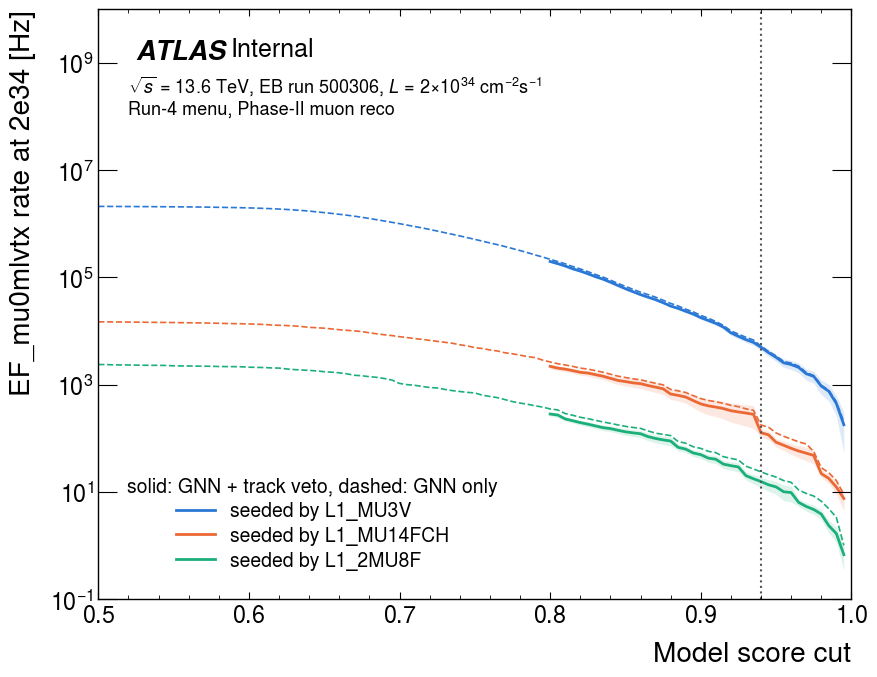

In [7]:
import sys
sys.path.insert(0, f"{DV_DIR}/test_rate")
from dv_seed_scan import eb_weights, ref_rate

RUN, TARGET_L = 500306, 2e34
rates_log = f"{EB_OUT}/ratesAnalysis/log.txt"
tables = sorted(glob.glob(f"{EB_OUT}/seedScan/*.txt"))
if not (os.path.exists(rates_log) and tables):
    print("EB rate inputs not there yet: run the rates step and dv_seed_scan.py first")
else:
    weights, lumi = eb_weights(RUN)
    w, sc, chn, bits = [], [], [], []
    for path in tables:
        with open(path) as fh:
            for line in fh:
                if line.startswith("#"):
                    items = line[1:].split()[4:]
                    continue
                f = line.split()
                ev, lb = int(f[0]), int(f[1])
                if ev not in weights or lb not in lumi:
                    continue
                w.append(weights[ev] * TARGET_L / (lumi[lb] * 1e30))
                chn.append(int(f[2]))
                sc.append(float(f[3]))
                bits.append([int(b) for b in f[4:]])
    w, sc, chn, bits = np.array(w), np.array(sc), np.array(chn, dtype=bool), np.array(bits, dtype=bool)
    l1 = {it: bits[:, k] for k, it in enumerate(items)}
    scale = ref_rate(rates_log, "L1_MU3V") / w[l1["L1_MU3V"]].sum()  # Hz per unit weight
    print(f"{len(w)} EB events from {len(tables)} files, L1_MU3V = {ref_rate(rates_log, 'L1_MU3V') / 1e6:.2f} MHz")

    EB_SEEDS = ["L1_MU3V", "L1_MU14FCH", "L1_2MU8F"]
    vcuts = CUTS[CUTS >= EB_JOB_CUT]
    with plot_context():
        fig, ax = plt.subplots(figsize=(9, 7))
        for seed, color in zip(EB_SEEDS, ["#2a78d6", "#eb6834", "#1baf7a"]):
            m = l1[seed] & l1["L1_MU3V"]
            rate = np.array([w[m & (sc > c)].sum() for c in CUTS]) * scale
            ok = rate > 0
            ax.plot(CUTS[ok], rate[ok], color=color, lw=1.2, ls="--")
            mv = m & chn
            vrate = np.array([w[mv & (sc > c)].sum() for c in vcuts]) * scale
            verr = np.array([np.sqrt((w[mv & (sc > c)] ** 2).sum()) for c in vcuts]) * scale
            ok = vrate > 0
            ax.plot(vcuts[ok], vrate[ok], color=color, lw=2, label=f"seeded by {seed}")
            ax.fill_between(vcuts[ok], (vrate - verr)[ok].clip(min=1e-3), (vrate + verr)[ok], color=color, alpha=0.15, lw=0)
            print(f"{seed:12s} rate at score > {NOMINAL_CUT}: GNN only {w[m & (sc > NOMINAL_CUT)].sum() * scale:8.1f} Hz, "
                  f"+ track veto {w[mv & (sc > NOMINAL_CUT)].sum() * scale:8.1f} Hz")
        ax.axvline(NOMINAL_CUT, color="#555555", lw=1.5, ls=":")
        ax.set_yscale("log")
        ax.set_xlabel("Model score cut")
        ax.set_ylabel("EF_mu0mlvtx rate at 2e34 [Hz]")
        ax.set_ylim(top=ax.get_ylim()[1] * 1000)  # headroom for the ATLAS label
        atlas_header(ax, r"$\sqrt{s}$ = 13.6 TeV, " "EB run 500306, $L$ = 2$\\times$10$^{34}$ cm$^{-2}$s$^{-1}$\nRun-4 menu, Phase-II muon reco", data=True, fontsize=13)
        ax.legend(frameon=False, loc="lower left", title="solid: GNN + track veto, dashed: GNN only")
        fig.tight_layout()
        plt.show()

## Summary tables

At the nominal cut: GNN + veto = chain decision (score ≥ job cut AND veto) AND score > 0.94; seed = that AND L1 TBP bit.

In [8]:
import re
import pandas as pd
import sys
sys.path.insert(0, f"{DV_DIR}/test_rate")
from dv_seed_scan import eb_weights, ref_rate

def read_tables(paths):
    """seed_table / seedScan files -> DataFrame (event lb chain score + one bool column per L1 item)"""
    frames = []
    for path in paths:
        with open(path) as fh:
            cols = fh.readline()[1:].split()
        frames.append(pd.read_csv(path, sep=r"\s+", comment="#", names=cols))
    df = pd.concat(frames, ignore_index=True)
    for c in df.columns[4:]:
        df[c] = df[c].astype(bool)
    df["chain"] = df["chain"].astype(bool) & df["L1_MU3V"]                # chain seed, see the introduction
    df["score"] = df["score"].where(df["L1_MU3V"], -1.0)
    df["gnn"] = df["score"] > NOMINAL_CUT          # GNN only
    df["pass"] = df["chain"] & df["gnn"]           # GNN + track veto
    return df

def label(sample):
    """directory name -> physics label"""
    m = re.match(r"(Haa4mu|a_mumu)_m(\d+)_ctau(\d+)_mu200", sample)
    if m:
        proc = "H→aa→4μ" if m.group(1) == "Haa4mu" else "a→μμ"
        return f"{proc}, m_a = {m.group(2)} GeV, cτ = {m.group(3)} mm"
    return {"JPSI_mu200": "J/ψ→μμ", "Zmumu_mu200": "Z→μμ", "ttbar_mu200": "tt̄", "jj_mu200": "dijets (jj)"}.get(sample, sample)

BACKGROUNDS = ["JPSI_mu200", "Zmumu_mu200", "ttbar_mu200", "jj_mu200"]
def sort_key(s):
    m = re.match(r"(Haa4mu|a_mumu)_m(\d+)_ctau", s)
    return (0, m.group(1) != "Haa4mu", int(m.group(2))) if m else (1, BACKGROUNDS.index(s), 0)

mc = {s: read_tables(sorted(glob.glob(f"{L1_DIR}/{s}/hlt/job_*/seed_table.txt")))
      for s in sorted((d for d in os.listdir(L1_DIR) if os.path.isdir(f"{L1_DIR}/{d}")), key=sort_key)}
print({s: len(df) for s, df in mc.items()})

{'Haa4mu_m4_ctau200_mu200': 2000, 'Haa4mu_m6_ctau200_mu200': 2000, 'Haa4mu_m8_ctau500_mu200': 2000, 'Haa4mu_m10_ctau500_mu200': 2000, 'a_mumu_m2_ctau100_mu200': 2000, 'a_mumu_m4_ctau100_mu200': 2000, 'a_mumu_m6_ctau100_mu200': 2000, 'a_mumu_m8_ctau500_mu200': 2000, 'a_mumu_m10_ctau500_mu200': 2000, 'a_mumu_m20_ctau500_mu200': 2000, 'a_mumu_m50_ctau1000_mu200': 2000, 'a_mumu_m100_ctau5000_mu200': 2000, 'JPSI_mu200': 2000, 'Zmumu_mu200': 2000, 'ttbar_mu200': 2000, 'jj_mu200': 2000}


### 1) Rate per L1 seed (EB run 500306, 2e34)

In [9]:
RUN, TARGET_L = 500306, 2e34
eb = read_tables(sorted(glob.glob(f"{EB_OUT}/seedScan/*.txt")))
weights, lumi = eb_weights(RUN)
eb = eb[eb["event"].isin(weights.keys()) & eb["lb"].isin(lumi.keys())]
eb["w"] = eb["event"].map(weights) * TARGET_L / (eb["lb"].map(lumi) * 1e30)
rates_log = f"{EB_OUT}/ratesAnalysis/log.txt"
scale = ref_rate(rates_log, "L1_MU3V") / eb.loc[eb["L1_MU3V"], "w"].sum()  # Hz per unit weight

def fmt_rate(r):
    return f"{r / 1e6:.2f} MHz" if r >= 1e6 else f"{r / 1e3:.3g} kHz" if r >= 1e3 else f"{r:.0f} Hz"

def fires(df, seed):
    """seed = one L1 item or a tuple of items (OR)"""
    items = seed if isinstance(seed, tuple) else (seed,)
    return df[list(items)].any(axis=1)

def seed_name(seed):
    return " OR ".join(seed) if isinstance(seed, tuple) else seed

# Two chains with the same HLT steps, one per seed, accept the OR of the seeds
OR_SEEDS = [("L1_MU14FCH", "L1_2MU8F"), ("L1_MU14FCH", "L1_2MU5VF"), ("L1_MU14FCH", "L1_2MU3V")]
rows = []
for seed in [c for c in eb.columns[4:] if c.startswith("L1_")] + OR_SEEDS:
    fired = fires(eb, seed)
    gnn = eb[fired & eb["L1_MU3V"] & eb["gnn"]]
    sel = eb[fired & eb["L1_MU3V"] & eb["pass"]]
    rows.append({"L1 seed": seed_name(seed) + (" (current)" if seed == "L1_MU3V" else ""),
                 "L1 rate": fmt_rate(eb.loc[fired, "w"].sum() * scale),
                 "GNN only": f"{fmt_rate(gnn['w'].sum() * scale)} ± {fmt_rate((gnn['w'] ** 2).sum() ** 0.5 * scale)}",
                 "GNN + track veto": f"{fmt_rate(sel['w'].sum() * scale)} ± {fmt_rate((sel['w'] ** 2).sum() ** 0.5 * scale)}",
                 "EB events passing: veto (GNN only)": f"{len(sel)} ({len(gnn)})"})
print(f"{len(eb)} EB events, {eb['event'].nunique()} unique")
pd.DataFrame(rows).set_index("L1 seed")

1029078 EB events, 1029078 unique


,L1 rate,GNN only,GNN + track veto,EB events passing: veto (GNN only)
L1 seed,,,,
L1_MU3V (current),2.15 MHz,5.22 kHz ± 654 Hz,4.96 kHz ± 652 Hz,1096 (1420)
L1_MU5VF,495 kHz,2.09 kHz ± 330 Hz,1.88 kHz ± 327 Hz,940 (1250)
L1_MU8F,242 kHz,1.03 kHz ± 106 Hz,875 Hz ± 99 Hz,838 (1129)
L1_MU8VF,72.1 kHz,355 Hz ± 49 Hz,257 Hz ± 41 Hz,687 (951)
L1_MU14FCH,16.4 kHz,176 Hz ± 27 Hz,127 Hz ± 22 Hz,497 (681)
L1_MU18VFCH,13.8 kHz,155 Hz ± 22 Hz,123 Hz ± 22 Hz,474 (647)
L1_2MU3V,113 kHz,376 Hz ± 33 Hz,326 Hz ± 32 Hz,362 (493)
L1_2MU5VF,8.14 kHz,54 Hz ± 8 Hz,41 Hz ± 8 Hz,137 (212)
L1_2MU8F,2.75 kHz,24 Hz ± 4 Hz,16 Hz ± 3 Hz,77 (125)


### 2) Efficiency per seed (Run-4 MC, μ = 200), GNN + track veto
"No L1" is the HLT alone ("No L1, GNN only" without the veto), the other columns also require the L1 item.

In [10]:
EFF_SEEDS = ["L1_MU8F", "L1_MU14FCH", "L1_2MU3V", "L1_2MU5VF", "L1_2MU8F", ("L1_MU14FCH", "L1_2MU8F")]
rows = {}
for s, df in mc.items():
    assert not (df["chain"] & ~df["L1_MU3V"]).any(), f"{s}: chain passes without L1_MU3V"
    row = {"N": len(df), "No L1, GNN only": 100 * df["gnn"].mean(), "No L1": 100 * df["pass"].mean()}
    row.update({seed_name(seed).replace("L1_", "").replace(" OR ", "|"): 100 * (df["pass"] & fires(df, seed)).mean()
                for seed in EFF_SEEDS})
    rows[label(s)] = row
eff = pd.DataFrame(rows).T
eff["N"] = eff["N"].astype(int)
eff.style.format({c: "{:.1f}%" for c in eff.columns if c != "N"})

,N,"No L1, GNN only",No L1,MU8F,MU14FCH,2MU3V,2MU5VF,2MU8F,MU14FCH|2MU8F
"H→aa→4μ, m_a = 4 GeV, cτ = 200 mm",2000,90.4%,86.8%,86.0%,79.8%,84.2%,78.5%,75.6%,83.3%
"H→aa→4μ, m_a = 6 GeV, cτ = 200 mm",2000,93.0%,89.5%,88.6%,81.5%,87.3%,82.2%,79.0%,85.4%
"H→aa→4μ, m_a = 8 GeV, cτ = 500 mm",2000,94.7%,90.0%,88.1%,76.0%,87.5%,79.0%,75.2%,82.9%
"H→aa→4μ, m_a = 10 GeV, cτ = 500 mm",2000,94.2%,90.8%,88.2%,73.5%,87.6%,77.0%,71.5%,81.4%
"a→μμ, m_a = 2 GeV, cτ = 100 mm",2000,66.5%,64.1%,58.7%,49.1%,42.9%,23.2%,18.1%,50.9%
"a→μμ, m_a = 4 GeV, cτ = 100 mm",2000,71.5%,69.2%,65.0%,54.0%,51.9%,34.4%,29.8%,57.4%
"a→μμ, m_a = 6 GeV, cτ = 100 mm",2000,73.8%,70.8%,67.0%,57.4%,58.8%,42.0%,37.8%,60.6%
"a→μμ, m_a = 8 GeV, cτ = 500 mm",2000,78.0%,74.3%,65.6%,46.9%,59.4%,36.4%,30.9%,52.0%
"a→μμ, m_a = 10 GeV, cτ = 500 mm",2000,78.6%,75.8%,66.4%,49.2%,61.1%,35.4%,29.5%,53.3%
"a→μμ, m_a = 20 GeV, cτ = 500 mm",2000,71.5%,68.8%,56.6%,39.1%,53.8%,27.4%,21.6%,42.8%


### 3) L1 firing rate on background MC (no ML filter)
Fraction of background events in which each L1 item fires (TBP), independent of the HLT chain.
For comparison, in Run-3 data L1_MU14FCH accepts well under 1% of crossings, so these show the fake-dominated L1 emulation.

In [11]:
L1_SHOW = ["L1_MU3V", "L1_MU8F", "L1_MU14FCH", "L1_2MU3V", "L1_2MU5VF", "L1_2MU8F"]
fire = pd.DataFrame({label(s): {it.replace("L1_", ""): 100 * mc[s][it].mean() for it in L1_SHOW}
                     for s in BACKGROUNDS if s in mc}).T
fire.style.format("{:.1f}%")

,MU3V,MU8F,MU14FCH,2MU3V,2MU5VF,2MU8F
J/ψ→μμ,99.2%,80.8%,19.9%,84.9%,65.0%,33.4%
Z→μμ,88.6%,77.6%,69.9%,59.0%,41.7%,37.8%
tt̄,78.5%,57.4%,45.6%,44.8%,21.1%,16.3%
dijets (jj),85.9%,58.0%,25.6%,62.8%,36.0%,28.0%


### 4) Unique rate against the primaries (EB run 500306, 2e34), GNN + track veto
Events with score > 0.94 AND the veto, where no chain enabled in `MC_pp_run4_Primary_prescale` fires
(`run_dv_unique.sh --scanDir rates_eb500306_trkveto --minScore 0.94 --requireChain`).

In [12]:
fired_path = f"{UNIQUE_OUT}/primaries_fired.txt"
if not os.path.exists(fired_path):
    print("not there yet: run ./run_dv_unique.sh first")
else:
    fired = pd.read_csv(fired_path, sep=r"\s+", comment="#", names=["event", "n_fired", "chains"])
    dv = eb[eb["pass"] & eb["L1_MU3V"]].merge(fired, on="event", how="left")
    if dv["n_fired"].isna().any():
        print(f"WARNING: {dv['n_fired'].isna().sum()} DV events not in the primaries rerun (counted as not unique)")
    dv["unique"] = dv["n_fired"].fillna(1) == 0
    rows = []
    for seed in ["L1_MU3V", "L1_MU8F", "L1_MU14FCH", "L1_2MU3V", "L1_2MU5VF", "L1_2MU8F", ("L1_MU14FCH", "L1_2MU8F")]:
        sel = dv[fires(dv, seed)]
        uni = sel[sel["unique"]]
        rows.append({"DV seeded by": seed_name(seed),
                     "rate": f"{fmt_rate(sel['w'].sum() * scale)} ± {fmt_rate((sel['w'] ** 2).sum() ** 0.5 * scale)}",
                     "unique rate": f"{fmt_rate(uni['w'].sum() * scale)} ± {fmt_rate((uni['w'] ** 2).sum() ** 0.5 * scale)}",
                     "unique fraction": f"{100 * uni['w'].sum() / sel['w'].sum():.0f}%",
                     "EB events (unique)": f"{len(sel)} ({len(uni)})"})
    display(pd.DataFrame(rows).set_index("DV seeded by"))

    # Which primaries take the DV events (weighted fraction of the L1_MU3V-seeded DV rate)
    over = dv[~dv["unique"] & dv["chains"].notna()].assign(chain=lambda d: d["chains"].str.split(",")).explode("chain")
    top = (over.groupby("chain")["w"].sum() / dv["w"].sum() * 100).sort_values(ascending=False).head(15)
    display(top.rename("% of DV rate also taken").to_frame().style.format("{:.1f}%"))

,rate,unique rate,unique fraction,EB events (unique)
DV seeded by,,,,
L1_MU3V,4.96 kHz ± 652 Hz,4.77 kHz ± 651 Hz,96%,1096 (871)
L1_MU8F,875 Hz ± 99 Hz,817 Hz ± 98 Hz,93%,838 (685)
L1_MU14FCH,127 Hz ± 22 Hz,100 Hz ± 17 Hz,79%,497 (428)
L1_2MU3V,326 Hz ± 32 Hz,309 Hz ± 31 Hz,95%,362 (296)
L1_2MU5VF,41 Hz ± 8 Hz,36 Hz ± 8 Hz,88%,137 (108)
L1_2MU8F,16 Hz ± 3 Hz,11 Hz ± 3 Hz,73%,77 (52)
L1_MU14FCH OR L1_2MU8F,137 Hz ± 22 Hz,108 Hz ± 17 Hz,79%,538 (460)


,% of DV rate also taken
chain,
EF_tau20_mediumGNTauDev1_L1cTAU20M,2.1%
EF_j50_pf_ftf_L1jJ40,1.7%
EF_tau20_mediumGNTau_L1cTAU20M,1.5%
EF_j100_a10sd_cssk_pf_jes_ftf_L1jJ40,0.2%
EF_mu24_msonly_L1MU14FCH,0.2%
EF_j100_pf_ftf_L1jJ40,0.1%
EF_j20_pf_ftf_preselj100_L1jJ70,0.1%
EF_mu11_mu6_bDimu2700_L1MU8VF_2MU5VF,0.0%
EF_mu11_mu6_bTau_L1MU8VF_2MU5VF,0.0%


L1_MU14FCH   score > 0.94: rate  127.1 Hz, unique   99.9 Hz
L1_2MU8F     score > 0.94: rate   15.6 Hz, unique   11.4 Hz


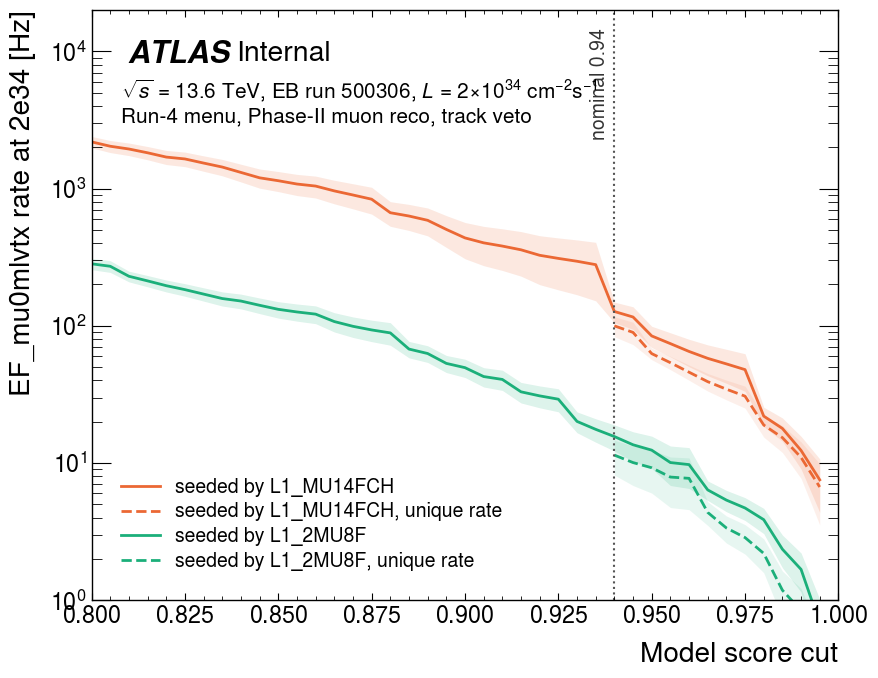

In [13]:
# Rate (solid) and unique rate against the primaries (dashed) vs score cut, per seed, GNN + track veto.
# The primaries were rerun only on the events with score > 0.94 and the veto, so the unique rate starts there
if os.path.exists(fired_path):
    with plot_context():
        fig, ax = plt.subplots(figsize=(9, 7))
        for seed, color in zip(["L1_MU14FCH", "L1_2MU8F"], ["#eb6834", "#1baf7a"]):
            m = fires(eb, seed) & eb["L1_MU3V"] & eb["chain"]
            rate = np.array([eb.loc[m & (eb["score"] > c), "w"].sum() for c in CUTS]) * scale
            err = np.array([np.sqrt((eb.loc[m & (eb["score"] > c), "w"] ** 2).sum()) for c in CUTS]) * scale
            ok = (rate > 0) & (CUTS >= EB_JOB_CUT)
            ax.plot(CUTS[ok], rate[ok], color=color, lw=2, label=f"seeded by {seed}")
            ax.fill_between(CUTS[ok], (rate - err)[ok].clip(min=1e-3), (rate + err)[ok], color=color, alpha=0.15, lw=0)
            u = dv[fires(dv, seed) & dv["unique"]]
            ucuts = CUTS[CUTS >= NOMINAL_CUT]
            urate = np.array([u.loc[u["score"] > c, "w"].sum() for c in ucuts]) * scale
            uerr = np.array([np.sqrt((u.loc[u["score"] > c, "w"] ** 2).sum()) for c in ucuts]) * scale
            ok = urate > 0
            ax.plot(ucuts[ok], urate[ok], color=color, lw=2, ls="--", label=f"seeded by {seed}, unique rate")
            ax.fill_between(ucuts[ok], (urate - uerr)[ok].clip(min=1e-3), (urate + uerr)[ok], color=color, alpha=0.10, lw=0)
            print(f"{seed:12s} score > {NOMINAL_CUT}: rate {eb.loc[m & (eb['score'] > NOMINAL_CUT), 'w'].sum() * scale:6.1f} Hz, "
                  f"unique {u.loc[u['score'] > NOMINAL_CUT, 'w'].sum() * scale:6.1f} Hz")
        ax.axvline(NOMINAL_CUT, color="#555555", lw=1.5, ls=":")
        ax.annotate(f"nominal {NOMINAL_CUT}", xy=(NOMINAL_CUT, 0.97), xycoords=ax.get_xaxis_transform(),
                    xytext=(-4, 0), textcoords="offset points", color="#333333", fontsize=14,
                    ha="right", va="top", rotation=90)
        ax.set_yscale("log")
        ax.set_xlabel("Model score cut")
        ax.set_ylabel("EF_mu0mlvtx rate at 2e34 [Hz]")
        ax.set_ylim(1, ax.get_ylim()[1] * 2)  # headroom for the ATLAS label
        atlas_header(ax, r"$\sqrt{s}$ = 13.6 TeV, " "EB run 500306, $L$ = 2$\\times$10$^{34}$ cm$^{-2}$s$^{-1}$\nRun-4 menu, Phase-II muon reco, track veto", data=True, fontsize=15)
        ax.legend(frameon=False, loc="lower left")
        fig.tight_layout()
        plt.show()

### 5) Chain time from the cost monitoring
#### EB run 500306 (Run-3 data)
`run_dv_cost.sh` with the track veto (`cost_eb500306_trkveto_{cpu,gpu}`), nightly 2026-11-09. Only the DV chain runs, so the
full-scan tracking is counted entirely in its time; in the full menu it is shared with the jet chains when they run it.
Dashed: the same chain without the veto (`test_rate_noTrackVeto`, same release). The algorithm table shows the step-3
part (FS tracking, vertexing, veto hypo) separately; it runs only on the events that pass step 2 (score > 0.94).

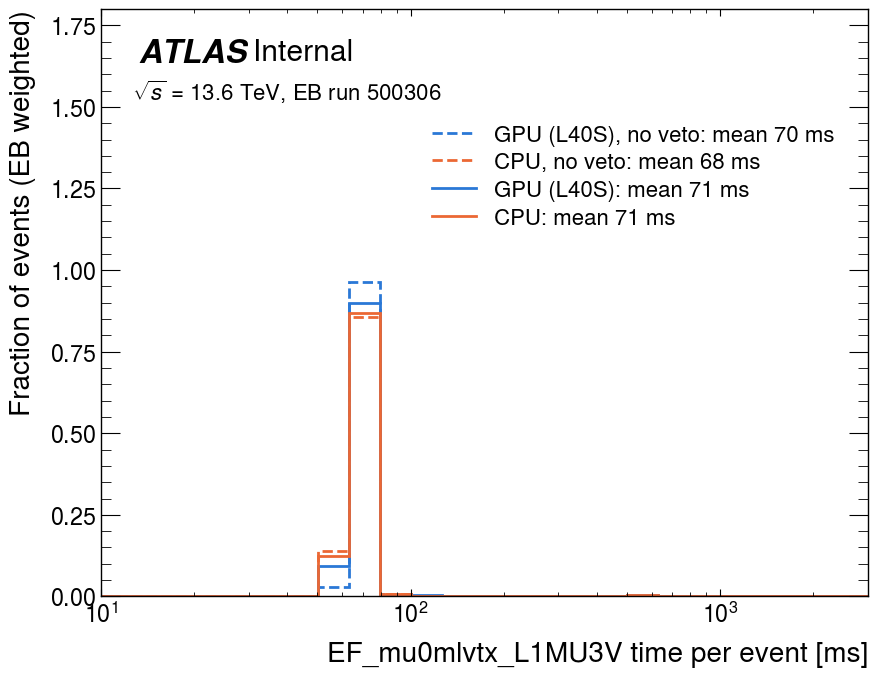

,events,mean [ms],median [ms],90% [ms],99% [ms]
"GPU (L40S), no veto",508.000000,69.9,71.1,77.8,79.4
"CPU, no veto",508.000000,68.4,70.0,77.6,79.4
GPU (L40S),508.000000,71.1,70.5,77.8,79.4
CPU,508.000000,71.0,70.2,77.7,79.4


,"GPU (L40S), no veto","CPU, no veto",GPU (L40S),CPU
TrigFastTrackFinder_fullScan,-,-,354.7,351.6
InDetSCTClusterization_fullScan_FSJETMETTrkRoI,-,-,43.8,44.3
InDetPixelClusterization_fullScan_FSJETMETTrkRoI,-,-,25.0,25.0
TrigSpacePointFinderfullScan,-,-,24.8,24.3
MdtRdoToMdtPrepData_SeedLess,19.4,18.9,18.7,18.8
TrigPixelRawDataProviderfullScan,-,-,13.8,13.8
MuonEtaHoughTransformAlgMlVtx,9.8,9.7,9.9,10.0
InDetTrigPriVxFinderfullScan,-,-,8.1,8.1
RpcRdoToRpcPrepData_SeedLess,7.2,7.1,7.2,7.2
MuonSpacePointMakerAlg_SeedLess,6.8,6.7,6.7,7.0


In [14]:
import uproot

CHAIN = "EF_mu0mlvtx_L1MU3V"

def hist_stats(h, probs=(0.5, 0.9, 0.99)):
    """mean (from the fill sums, as TH1::GetMean) and quantiles (linear within a bin)"""
    w, edges = h.values(), h.axis().edges()
    cum = np.cumsum(w) / w.sum()
    qs = [np.interp(p, np.concatenate([[0], cum]), edges) for p in probs]
    return h.member("fTsumwx") / h.member("fTsumw"), qs

INFERENCE_ALG = "InferenceAlgMlVtx"

def alg_means(f):
    """algorithm of the chain -> mean time per event [ms]"""
    prefix, means = f"All/Chain_Algorithm_HLT/{CHAIN}__", {}
    for k in f.keys(cycle=False):
        if k.startswith(prefix) and k.endswith("_Time_perEvent") and not k.endswith("FirstTime_perEvent"):
            ha = f[k]
            if ha.member("fTsumw") > 0:  # empty: the algorithm never ran
                means[k[len(prefix):].split("/")[0]] = ha.member("fTsumwx") / ha.member("fTsumw")
    return means

def show_cost(runs, title, weight_label, inference_from=None, data=False):
    """runs: {label: run_dv_cost.sh output dir}; the dirs that exist are shown.
    inference_from: {label: other label or output dir} takes the DV inference time of the other run (e.g.
    when the GPU was shared during this one); the chain time is shifted by the difference: exact for the
    mean, approximate for the quantiles and the plot.
    The cost histograms have fixed log bins (10 per decade, set in TrigCostAnalysis)."""
    inference_from = inference_from or {}
    cost = {}
    for name, d in runs.items():
        path = f"{d}/TrigCostRoot_Results.root"
        if os.path.exists(path):
            cost[name] = uproot.open(path)
        else:
            print(f"{name}: no {path}")
    if not cost:
        return
    algs = {name: alg_means(f) for name, f in cost.items()}
    shift = {}
    for name, other in inference_from.items():
        if name not in algs:
            continue
        src_algs = algs[other] if other in algs else alg_means(uproot.open(f"{other}/TrigCostRoot_Results.root"))
        shift[name] = src_algs[INFERENCE_ALG] - algs[name][INFERENCE_ALG]
        #print(f"{name}: {INFERENCE_ALG} {algs[name][INFERENCE_ALG]:.1f} ms replaced by {src_algs[INFERENCE_ALG]:.1f} ms "
        #      f"of '{other}', chain time shifted by {shift[name]:+.1f} ms (quantiles and plot approximate)")
        algs[name][INFERENCE_ALG] = src_algs[INFERENCE_ALG]
    rows = {}
    with plot_context():
        fig, ax = plt.subplots(figsize=(9, 7))
        # Up to two pairs: same colour for the same device, dashed for the first pair
        styles = [("#2a78d6", "--"), ("#eb6834", "--"), ("#2a78d6", "-"), ("#eb6834", "-")] if len(cost) > 2 \
            else [("#2a78d6", "-"), ("#eb6834", "-")]
        for (name, f), (color, ls) in zip(cost.items(), styles):
            h = f[f"All/Chain_HLT/{CHAIN}/All_Chain_HLT_{CHAIN}_Time_perEvent"]
            mean, (q50, q90, q99) = hist_stats(h)
            d = shift.get(name, 0.0)
            mean, q50, q90, q99 = mean + d, q50 + d, q90 + d, q99 + d
            rows[name] = {"events": int(h.member("fEntries")), "mean [ms]": mean, "median [ms]": q50,
                          "90% [ms]": q90, "99% [ms]": q99}
            w, edges = h.values(), h.axis().edges() + d
            ax.stairs(w / w.sum(), edges, color=color, ls=ls, lw=2, label=f"{name}: mean {mean:.0f} ms")
        ax.set_xscale("log")
        ax.set_xlim(10, 3000)  # the FS tracking events reach ~2 s
        ax.set_ylim(0, ax.get_ylim()[1] * 1.5)  # headroom for the ATLAS label and the legend
        ax.set_xlabel(f"{CHAIN} time per event [ms]")
        ax.set_ylabel(f"Fraction of events ({weight_label})")
        atlas_header(ax, title, data=data, fontsize=16)
        ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(1, 0.86), fontsize=16)
        fig.tight_layout()
        plt.show()

    display(pd.DataFrame(rows).T.style.format({c: "{:.1f}" for c in ["mean [ms]", "median [ms]", "90% [ms]", "99% [ms]"]}))
    alg_df = pd.DataFrame(algs)
    # rank by the largest column, so the step-3 algorithms (NaN without the veto) are kept
    alg_df = alg_df.loc[alg_df.max(axis=1).sort_values(ascending=False).index].head(20)
    display(alg_df.style.format("{:.1f}", na_rep="-").set_caption(
        "Mean time per event the algorithm runs on [ms]; step 3 runs only on the events passing step 2"))

show_cost({"GPU (L40S), no veto": f"{NOVETO_DIR}/cost_eb500306_gpu",
           "CPU, no veto": f"{NOVETO_DIR}/cost_eb500306_cpu",
           "GPU (L40S)": f"{OUT_DIR}/cost_eb500306_trkveto_gpu",
           "CPU": f"{OUT_DIR}/cost_eb500306_trkveto_cpu"},
          r"$\sqrt{s}$ = 13.6 TeV, EB run 500306", "EB weighted", data=True)

#### Run-4 ttbar, μ = 200
500 events of the ttbar file, every event weighted equally, nightly 2026-11-09. Dashed: without the veto.
With the veto the chain runs on all 500 events, without it on the 405 L1_MU3V events (`FSNOSEED`, see the introduction),
so the per-event means are over different event sets: the extra 95 events pass only through the cheap steps.


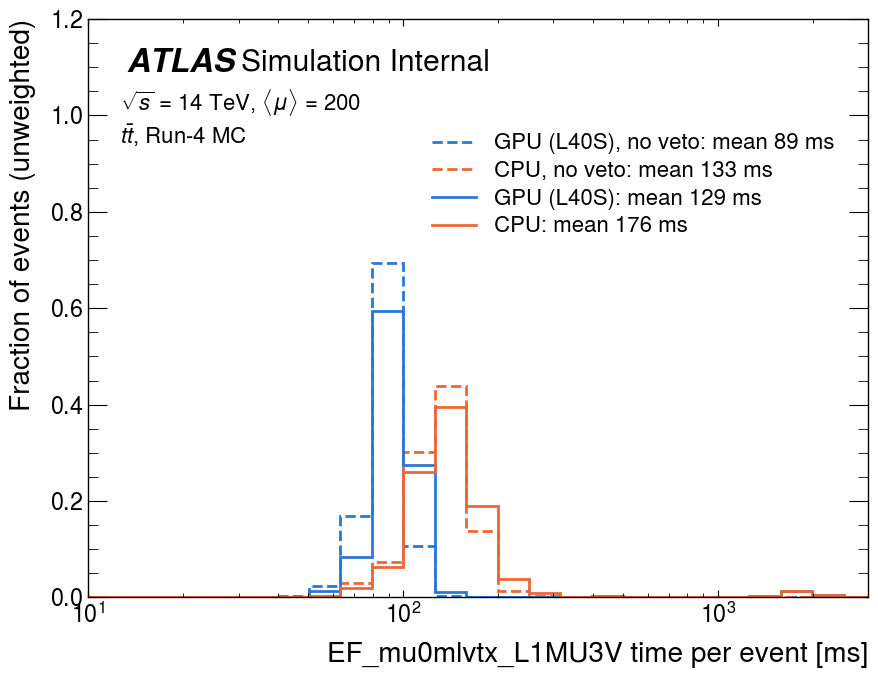

,events,mean [ms],median [ms],90% [ms],99% [ms]
"GPU (L40S), no veto",405.000000,89.1,88.5,102.7,124.7
"CPU, no veto",405.000000,132.9,132.8,174.2,219.7
GPU (L40S),500.000000,129.4,93.4,119.7,1819.4
CPU,500.000000,175.6,138.6,193.0,1819.4


,"GPU (L40S), no veto","CPU, no veto",GPU (L40S),CPU
TrigFastTrackFinder_fullScan,-,-,500.1,495.2
ITkStripClusterization_fullScan,-,-,394.0,387.1
ITkPixelClusterization_fullScan,-,-,369.8,378.2
ITkTrigTrackParticleCnvAlgfullScan,-,-,285.4,284.9
ITkTrigSiTrackerSpacePointFinderfullScan,-,-,146.5,140.5
InferenceAlgMlVtx,9.5,52.3,9.5,52.3
InDetTrigPriVxFinderfullScan,-,-,32.2,32.6
MdtRdoToMdtPrepData_SeedLess,14.0,14.3,14.5,18.5
MuonNswSegmentFinderAlgMlVtx,10.2,10.3,10.5,10.5
MMRdoToMMPrepData_SeedLess,7.0,7.0,8.4,8.3


In [15]:
show_cost({"GPU (L40S), no veto": f"{NOVETO_DIR}/cost_ttbar_mu200_gpu",
           "CPU, no veto": f"{NOVETO_DIR}/cost_ttbar_mu200_cpu",
           "GPU (L40S)": f"{OUT_DIR}/cost_ttbar_mu200_trkveto_gpu",
           "CPU": f"{OUT_DIR}/cost_ttbar_mu200_trkveto_cpu"},
          f"{MC_LABEL}\n" + r"$t\bar{t}$, Run-4 MC", "unweighted")
